In [1]:
%pip install numpy matplotlib pillow

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 33.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 57.4 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 48.8 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

folder = Path.cwd()

print("Current folder:", folder)
print("Weights found:", (folder / "sample_weight.pkl").is_file())

image_folder = folder / "test_images"
images = list(image_folder.glob("*.png"))

print("Number of test images:", len(images))

Current folder: /Users/sashikiran/Desktop/ece-5831-2026-assignments/MNIST Class Implementation and Testing
Weights found: True
Number of test images: 50


Image size: (28, 28)
Image mode: L


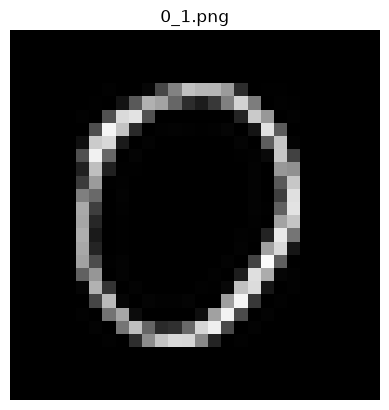

In [4]:
image_path = image_folder / "0_1.png"

with Image.open(image_path) as image:
    print("Image size:", image.size)
    print("Image mode:", image.mode)
    pixels = np.array(image)

plt.imshow(pixels, cmap="gray", vmin=0, vmax=255)
plt.title("0_1.png")
plt.axis("off")
plt.show()

In [5]:
import pickle

class Mnist:
    def __init__(self, weight_path="sample_weight.pkl"):
        # Load the supplied trained weights and biases.
        with open(weight_path, "rb") as file:
            self.network = pickle.load(file, encoding="latin1")

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x))
        return exp_x / np.sum(exp_x)

    def predict(self, image_path):
        # Read the prepared 28 × 28 grayscale image.
        with Image.open(image_path) as image:
            if image.size != (28, 28) or image.mode != "L":
                raise ValueError("Image must be 28 × 28 grayscale.")

            pixels = np.array(image, dtype=np.float32)

        # Convert to 784 inputs and normalize to 0–1.
        x = pixels.flatten() / 255.0

        W1 = self.network["W1"]
        W2 = self.network["W2"]
        W3 = self.network["W3"]
        b1 = self.network["b1"]
        b2 = self.network["b2"]
        b3 = self.network["b3"]

        # Forward propagation.
        layer1 = self.sigmoid(np.dot(x, W1) + b1)
        layer2 = self.sigmoid(np.dot(layer1, W2) + b2)
        output = np.dot(layer2, W3) + b3

        probabilities = self.softmax(output)
        predicted_digit = int(np.argmax(probabilities))

        return predicted_digit, pixels

In [6]:
mnist = Mnist(folder / "sample_weight.pkl")
print("MNIST model loaded successfully!")

MNIST model loaded successfully!


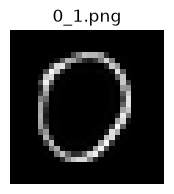

Success: Image 0_1.png is for digit 0 is recognized as 0.


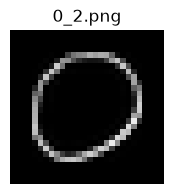

Fail: Image 0_2.png is for digit 0 but the inference result is 3.


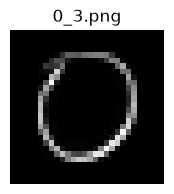

Success: Image 0_3.png is for digit 0 is recognized as 0.


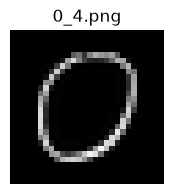

Success: Image 0_4.png is for digit 0 is recognized as 0.


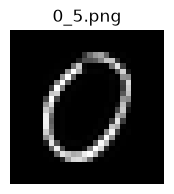

Success: Image 0_5.png is for digit 0 is recognized as 0.


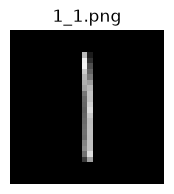

Success: Image 1_1.png is for digit 1 is recognized as 1.


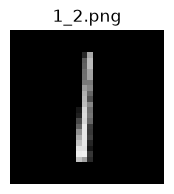

Success: Image 1_2.png is for digit 1 is recognized as 1.


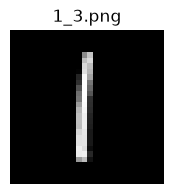

Success: Image 1_3.png is for digit 1 is recognized as 1.


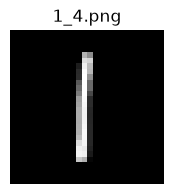

Success: Image 1_4.png is for digit 1 is recognized as 1.


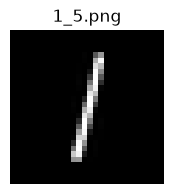

Success: Image 1_5.png is for digit 1 is recognized as 1.


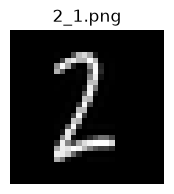

Success: Image 2_1.png is for digit 2 is recognized as 2.


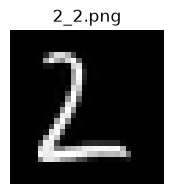

Fail: Image 2_2.png is for digit 2 but the inference result is 0.


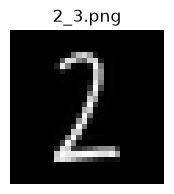

Success: Image 2_3.png is for digit 2 is recognized as 2.


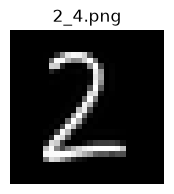

Success: Image 2_4.png is for digit 2 is recognized as 2.


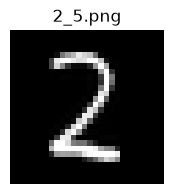

Success: Image 2_5.png is for digit 2 is recognized as 2.


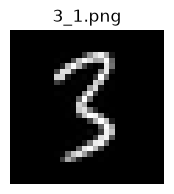

Success: Image 3_1.png is for digit 3 is recognized as 3.


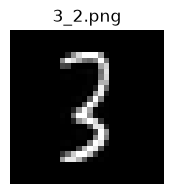

Success: Image 3_2.png is for digit 3 is recognized as 3.


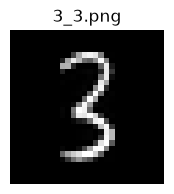

Success: Image 3_3.png is for digit 3 is recognized as 3.


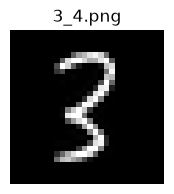

Success: Image 3_4.png is for digit 3 is recognized as 3.


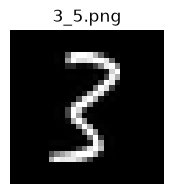

Success: Image 3_5.png is for digit 3 is recognized as 3.


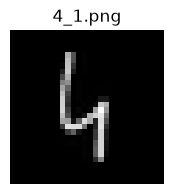

Success: Image 4_1.png is for digit 4 is recognized as 4.


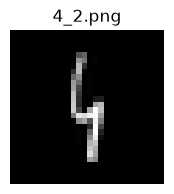

Success: Image 4_2.png is for digit 4 is recognized as 4.


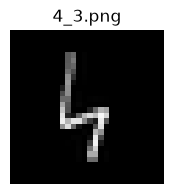

Success: Image 4_3.png is for digit 4 is recognized as 4.


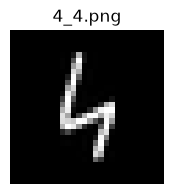

Success: Image 4_4.png is for digit 4 is recognized as 4.


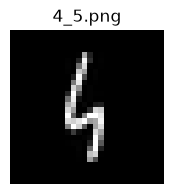

Success: Image 4_5.png is for digit 4 is recognized as 4.


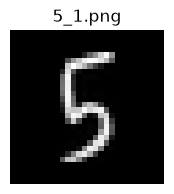

Success: Image 5_1.png is for digit 5 is recognized as 5.


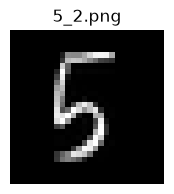

Fail: Image 5_2.png is for digit 5 but the inference result is 6.


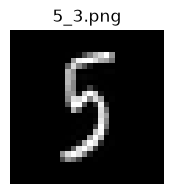

Success: Image 5_3.png is for digit 5 is recognized as 5.


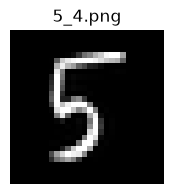

Success: Image 5_4.png is for digit 5 is recognized as 5.


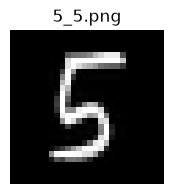

Success: Image 5_5.png is for digit 5 is recognized as 5.


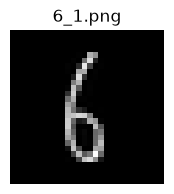

Success: Image 6_1.png is for digit 6 is recognized as 6.


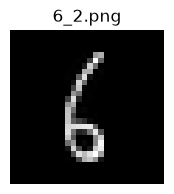

Success: Image 6_2.png is for digit 6 is recognized as 6.


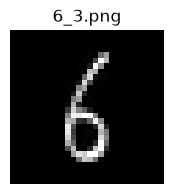

Success: Image 6_3.png is for digit 6 is recognized as 6.


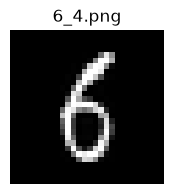

Fail: Image 6_4.png is for digit 6 but the inference result is 5.


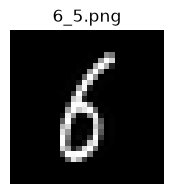

Success: Image 6_5.png is for digit 6 is recognized as 6.


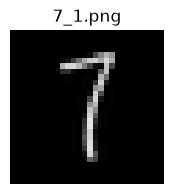

Fail: Image 7_1.png is for digit 7 but the inference result is 1.


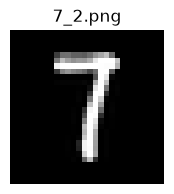

Fail: Image 7_2.png is for digit 7 but the inference result is 3.


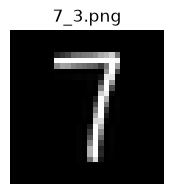

Fail: Image 7_3.png is for digit 7 but the inference result is 3.


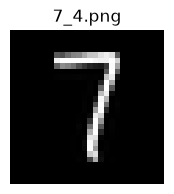

Fail: Image 7_4.png is for digit 7 but the inference result is 2.


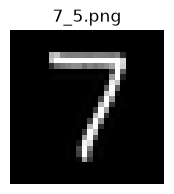

Fail: Image 7_5.png is for digit 7 but the inference result is 2.


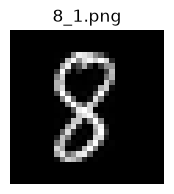

Success: Image 8_1.png is for digit 8 is recognized as 8.


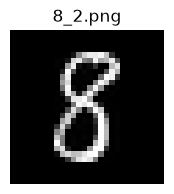

Success: Image 8_2.png is for digit 8 is recognized as 8.


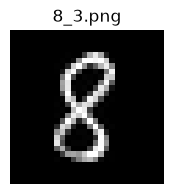

Success: Image 8_3.png is for digit 8 is recognized as 8.


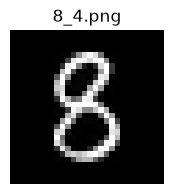

Success: Image 8_4.png is for digit 8 is recognized as 8.


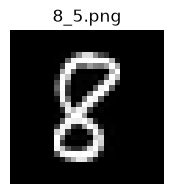

Success: Image 8_5.png is for digit 8 is recognized as 8.


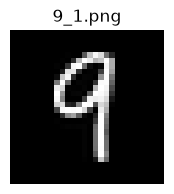

Fail: Image 9_1.png is for digit 9 but the inference result is 3.


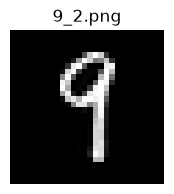

Fail: Image 9_2.png is for digit 9 but the inference result is 3.


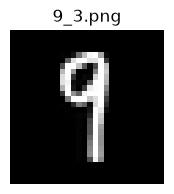

Fail: Image 9_3.png is for digit 9 but the inference result is 3.


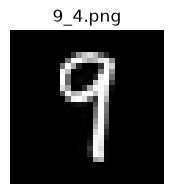

Fail: Image 9_4.png is for digit 9 but the inference result is 3.


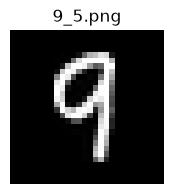

Fail: Image 9_5.png is for digit 9 but the inference result is 3.

Correct predictions: 36/50
Accuracy: 72.00%


In [7]:
correct = 0
total = 0

for digit in range(10):
    for version in range(1, 6):
        filename = f"{digit}_{version}.png"
        image_path = image_folder / filename

        predicted_digit, pixels = mnist.predict(image_path)

        plt.figure(figsize=(2, 2))
        plt.imshow(pixels, cmap="gray", vmin=0, vmax=255)
        plt.title(filename)
        plt.axis("off")
        plt.show()

        if predicted_digit == digit:
            print(
                f"Success: Image {filename} is for digit {digit} "
                f"is recognized as {predicted_digit}."
            )
            correct += 1
        else:
            print(
                f"Fail: Image {filename} is for digit {digit} "
                f"but the inference result is {predicted_digit}."
            )

        total += 1

print(f"\nCorrect predictions: {correct}/{total}")
print(f"Accuracy: {correct / total:.2%}")